In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [3]:
import seaborn as sns

In [4]:
df = sns.load_dataset("taxis")

In [5]:
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [6]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [7]:
df=df.dropna(subset=["pickup_zone","dropoff_zone"])

In [8]:
df["payment"]=df["payment"].fillna(df["payment"].mode()[0])

In [9]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

**Visualisations using Matplotlib**

In [11]:
df["pickup"]=pd.to_datetime(df["pickup"])

In [12]:
df.dtypes

pickup             datetime64[us]
dropoff            datetime64[us]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                         str
payment                       str
pickup_zone                   str
dropoff_zone                  str
pickup_borough                str
dropoff_borough               str
dtype: object

In [13]:
df["pickup"]=pd.to_datetime(df["pickup"])

<function matplotlib.pyplot.show(close=None, block=None)>

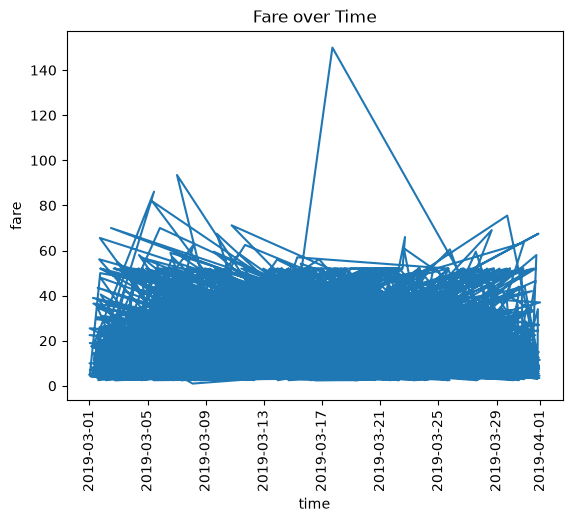

In [14]:
plt.plot(df["pickup"],df["fare"])
plt.xlabel("time")
plt.ylabel("fare")
plt.title("Fare over Time")
plt.xticks(rotation=90)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

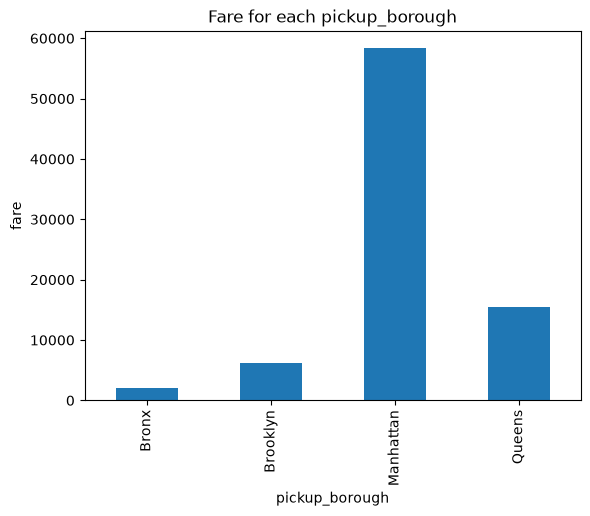

In [15]:
df.groupby("pickup_borough")["fare"].sum().plot(kind="bar")
plt.ylabel("fare")
plt.title("Fare for each pickup_borough")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

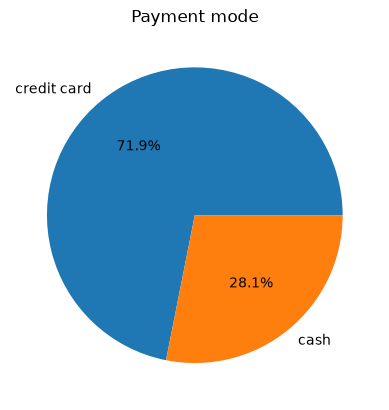

In [16]:
plt.pie(df["payment"].value_counts(),labels=df["payment"].unique(),autopct="%1.1f%%")
plt.title("Payment mode")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

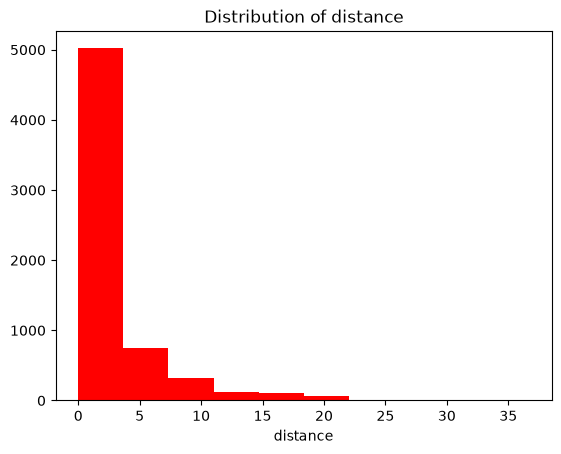

In [17]:
plt.hist(df["distance"],bins=10,color="Red")
plt.title("Distribution of distance")
plt.xlabel("distance")
plt.show

In [18]:
df["pickup_borough"].unique()

<ArrowStringArray>
['Manhattan', 'Queens', 'Bronx', 'Brooklyn']
Length: 4, dtype: str

In [19]:
d1=df.loc[(df["pickup_borough"]=="Manhattan"),"tip"]

In [20]:
d2=df.loc[(df["pickup_borough"]=="Queens"),"tip"]

In [21]:
d3=df.loc[(df["pickup_borough"]=="Bronx"),"tip"]

In [22]:
d4=df.loc[(df["pickup_borough"]=="Brooklyn"),"tip"]

In [23]:
df1=[d1,d2,d3,d4]

<function matplotlib.pyplot.show(close=None, block=None)>

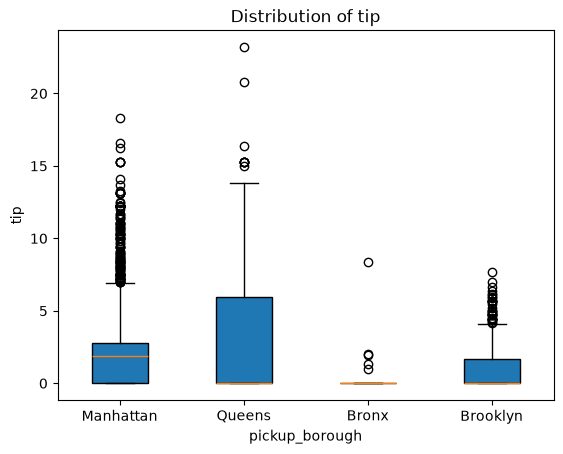

In [24]:
plt.boxplot(df1,patch_artist=True,tick_labels=["Manhattan","Queens","Bronx","Brooklyn"])
plt.xlabel("pickup_borough")
plt.ylabel("tip")
plt.title("Distribution of tip")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

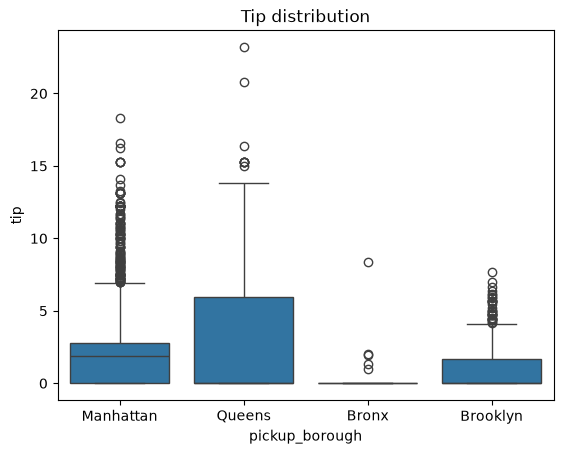

In [25]:
sns.boxplot(data=df,x="pickup_borough",y="tip")
plt.title("Tip distribution")
plt.show

In [26]:
##Visualisations using Seaborn

Text(0.5, 1.0, 'Trips in each pickup borough')

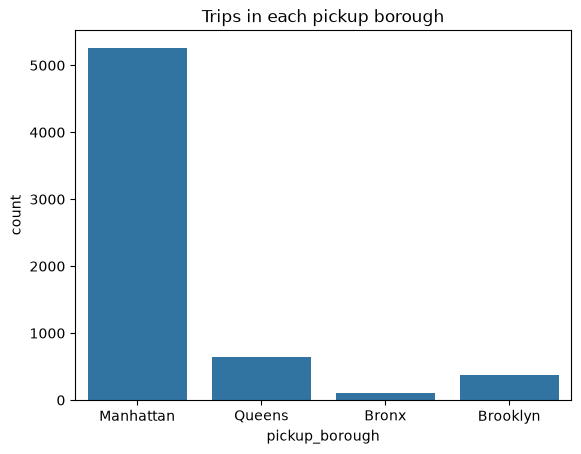

In [27]:
sns.countplot(x="pickup_borough",data=df)
plt.title("Trips in each pickup borough")

<function matplotlib.pyplot.show(close=None, block=None)>

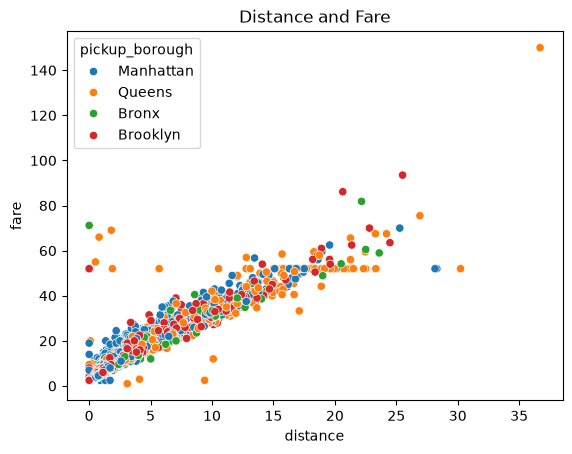

In [28]:
sns.scatterplot(data=df,x="distance",y="fare",hue="pickup_borough")
plt.title("Distance and Fare")
plt.show

In [29]:
corr=df[["distance","fare","tip","tolls","total"]].corr()

In [30]:
corr

,distance,fare,tip,tolls,total
distance,1.000000,0.947021,0.475378,0.642899,0.928371
fare,0.947021,1.000000,0.485655,0.618184,0.972376
tip,0.475378,0.485655,1.000000,0.412787,0.649050
tolls,0.642899,0.618184,0.412787,1.000000,0.691506
total,0.928371,0.972376,0.649050,0.691506,1.000000


<function matplotlib.pyplot.show(close=None, block=None)>

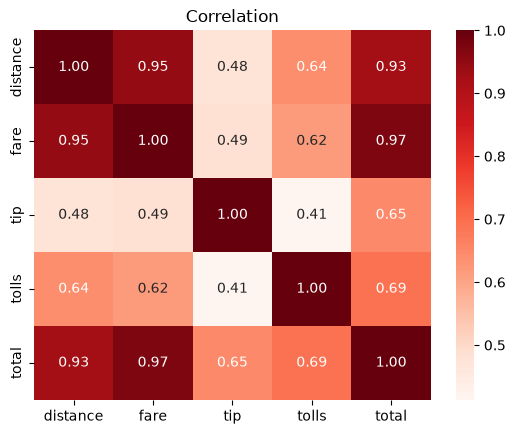

In [31]:
sns.heatmap(corr,annot=True,fmt=".2f",cmap="Reds")
plt.title("Correlation")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

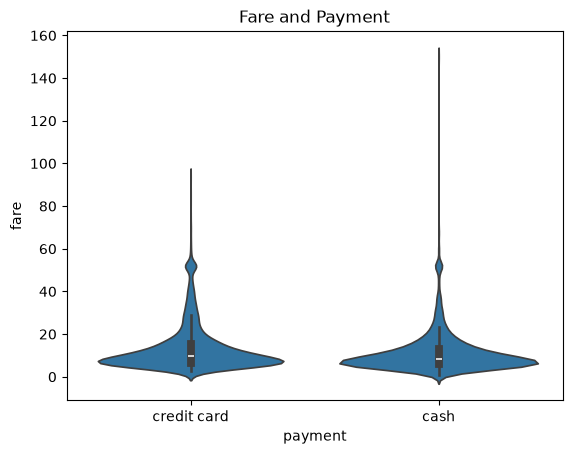

In [32]:
sns.violinplot(data=df,x="payment",y="fare")
plt.title("Fare and Payment")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

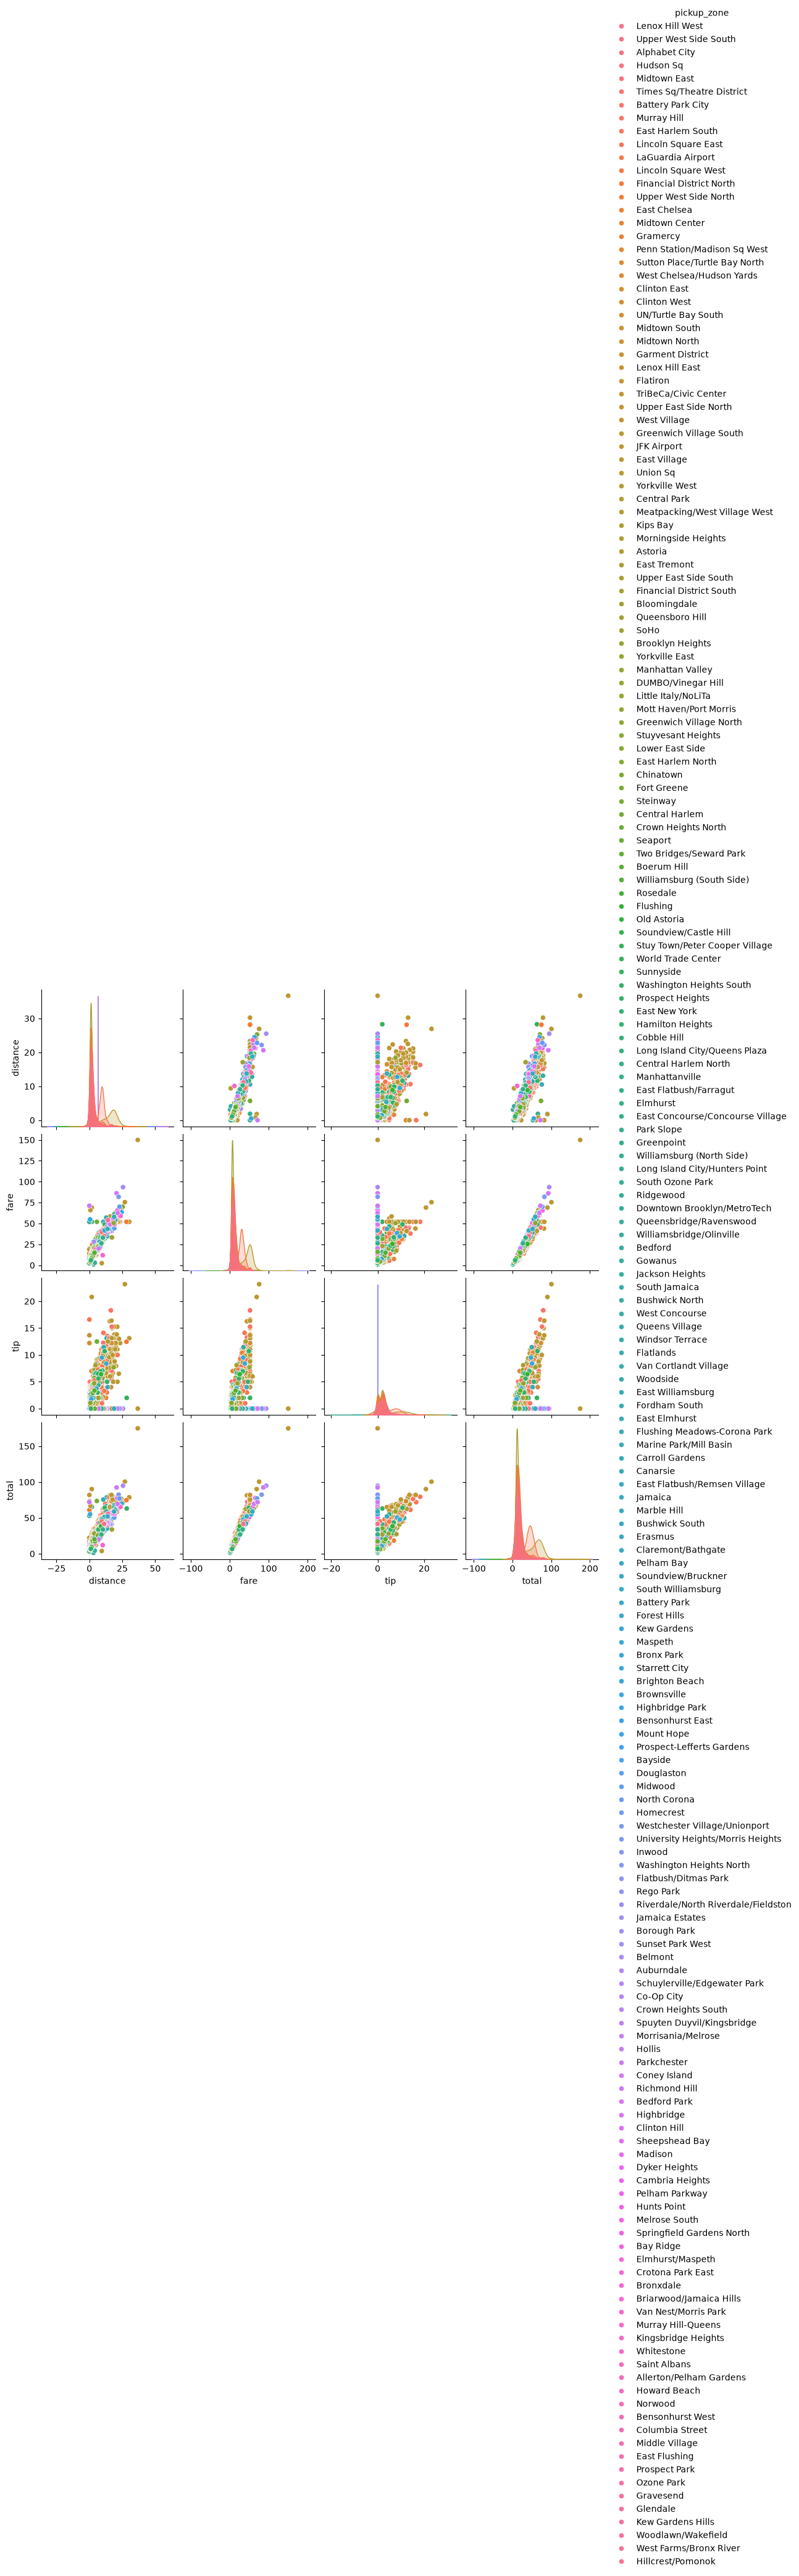

In [33]:
sns.pairplot(data=df,vars=["distance","fare","tip","total"],hue="pickup_zone")
plt.show